# Часть 1. Проверка гипотезы в Python и составление аналитической записки

Вы предобработали данные в SQL, и теперь они готовы для проверки гипотезы в Python. Загрузите данные пользователей из Москвы и Санкт-Петербурга c суммой часов их активности из файла yandex_knigi_data.csv. Если работаете локально, скачать файл можно по ссылке.

Проверьте наличие дубликатов в идентификаторах пользователей. Сравните размеры групп, их статистики и распределение.

Напомним, как выглядит гипотеза: пользователи из Санкт-Петербурга проводят в среднем больше времени за чтением и прослушиванием книг в приложении, чем пользователи из Москвы. Попробуйте статистически это доказать, используя одностороннюю проверку гипотезы с двумя выборками:

Нулевая гипотеза $H_0: \mu_{\text{СПб}} \leq \mu_{\text{Москва}}$ <br> Среднее время активности пользователей в Санкт-Петербурге не больше, чем в Москве.

Альтернативная гипотеза $H_1: \mu_{\text{СПб}} > \mu_{\text{Москва}}$ <br> Среднее время активности пользователей в Санкт-Петербурге больше, и это различие статистически значимо.

По результатам анализа данных подготовьте аналитическую записку, в которой опишите:

Выбранный тип t-теста и уровень статистической значимости.

Результат теста, или p-value.

Вывод на основе полученного p-value, то есть интерпретацию результатов.

Одну или две возможные причины, объясняющие полученные результаты.

## Напишите заголовок первой части проекта здесь

- Автор: Бавин Максим
- Дата: 11.08.26

## Цели и задачи проекта

<font color='#777778'>В этом блоке перечислите цель проекта и те задачи, которые вы решаете. Можно использовать описания проекта, но будет полезно, если вы сформулируете основную цель проекта самостоятельно.</font>

Цель проекта:
Провести анализ активности пользователей сервиса Яндекс Книги, рассчитать ключевые метрики (MAU, LTV, Retention Rate, средняя выручка на час) и проверить статистическую гипотезу о различии в поведении пользователей из Москвы и Санкт-Петербурга

Задачи:
- Расчёт MAU авторов и произведений - определить топ-3 авторов и произведений по числу уникальных пользователей в ноябре
- Расчёт Retention Rate - оценить удержание пользователей, пришедших 2 декабря, и построить кривую удержания
- Расчёт LTV - сравнить среднюю пожизненную ценность пользователей из Москвы и Санкт-Петербурга
- Расчёт средней выручки на час - оценить эффективность монетизации для сентября–ноября
- Подготовка данных в SQL - сформировать агрегированную таблицу с суммой часов активности для пользователей двух городов
- Проверка гипотезы в Python - статистически сравнить среднее время активности пользователей из Санкт-Петербурга и Москвы
- Составление аналитической записки - интерпретировать результаты теста, сформулировать выводы и возможные причины выявленных различий

## Описание данных

<font color='#777778'>Здесь приведите описание данных.</font>

Таблицы этого проекта содержат данные о чтении и прослушивании контента в сервисе Яндекс Книги, которые включают информацию о пользователях, платформах, времени, длительности сессий и типах контента. Данные представлены за период с 1 сентября по 11 декабря 2024 года. В вашем распоряжении будет несколько таблиц.

Таблица bookmate.audition содержит данные об активности пользователей и состоит из следующих полей:
- audition_id — уникальный идентификатор сессии чтения или прослушивания;
- puid — идентификатор пользователя;
- usage_platform_ru — название платформы, с помощью которой пользователь слушал контент;
- msk_business_dt_str — дата события в формате строки (московское время);
- app_version — версия приложения, которая использовалась для чтения или прослушивания;
- adult_content_flg — был ли это контент для взрослых: True или False;
- hours — длительность чтения или прослушивания в часах;
- hours_sessions_long — продолжительность длинных сессий чтения или прослушивания в часах;
- kids_content_flg — был ли это детский контент: True или False;
- main_content_id — идентификатор основного контента;
- usage_geo_id — идентификатор географического местоположения.
Таблица bookmate.content содержит данные о контенте и состоит из следующих полей:
- main_content_id — идентификатор основного контента;
- main_author_id — идентификатор основного автора контента;
- main_content_type — тип контента;
- main_content_name— название контента;
- main_content_duration_hours — длительность контента в часах;
- published_topic_title_list — список жанров контента.
Таблица bookmate.author содержит данные об авторах контента и состоит из следующих полей:
- main_author_id — идентификатор основного автора контента;
- main_author_name — имя основного автора контента.
Таблица bookmate.geo содержит данные о местоположении и состоит из следующих полей:
- usage_geo_id — идентификатор географического положения;
- usage_geo_id_name — город или регион географического положения;
- usage_country_name — страна географического положения.

## Содержимое проекта

<font color='#777778'>Перечислите основные шаги проекта или напишите оглавление. Используйте описание проекта, чтобы зафиксировать основные шаги.</font>

---

1 Расчёт MAU авторов и произведений
- Определение топ-3 авторов по числу уникальных пользователей в ноябре
- Определение топ-3 произведений по MAU с указанием жанров и авторов

2 Расчёт Retention Rate
- Анализ удержания пользователей, активных 2 декабря 2024 года
- Построение кривой удержания по дням с округлением

3 Расчёт LTV
- Оценка средней пожизненной ценности пользователей в Москве и Санкт-Петербурге
- Сравнение LTV между городами

4 Расчёт средней выручки на час
- Вычисление MAU, суммарных часов и средней выручки за час для сентября-ноября

5 Подготовка данных в SQL для проверки гипотезы
- Агрегация суммарных часов активности пользователей из Москвы и Санкт-Петербурга

6 Проверка гипотезы в Python
- Загрузка и первичный анализ данных
- Выбор статистического теста
- Расчёт p-value и интерпретация результатов

7 Аналитическая записка
- Описание выбранного теста и уровня значимости
- Результаты теста и выводы
- Возможные причины выявленных различий

## 1. Загрузка данных и знакомство с ними

Загрузите данные пользователей из Москвы и Санкт-Петербурга c их активностью (суммой часов чтения и прослушивания) из файла `/datasets/yandex_knigi_data.csv`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats as st

df = pd.read_csv('/datasets/yandex_knigi_data.csv')

# Агрегируем часы на пользователя
df = df.groupby(['city', 'puid'], as_index=False)['hours'].sum()

# Удаляем дубликаты по puid
df = df.drop_duplicates(subset=['puid'], keep='first')

# Первичный просмотр данных
print("Первые 5 строк:")
print(df.head())

print("\nИнформация о данных:")
print(df.info())

print("Пропуски:\n", df.isna().sum())
print("\nЯвных дубликатов:", df.duplicated().sum())
print("Уникальных puid:", df['puid'].nunique())
print("Неявных дубликатов по puid:", len(df) - df['puid'].nunique())

Первые 5 строк:
     city    puid       hours
0  Москва    9668   26.167776
1  Москва   16598   82.111217
2  Москва   80401    4.656906
3  Москва  140205    1.840556
4  Москва  248755  151.326434

Информация о данных:
<class 'pandas.core.frame.DataFrame'>
Int64Index: 8540 entries, 0 to 8783
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   city    8540 non-null   object 
 1   puid    8540 non-null   int64  
 2   hours   8540 non-null   float64
dtypes: float64(1), int64(1), object(1)
memory usage: 266.9+ KB
None
Пропуски:
 city     0
puid     0
hours    0
dtype: int64

Явных дубликатов: 0
Уникальных puid: 8540
Неявных дубликатов по puid: 0


Вывод по полученным данным
- Пропусков в данных нет, все столбцы полностью заполнены
- Явных дубликатов строк не обнаружено
- Общее количество строк 8784, уникальных пользователей 8540. Это означает, что 244 строки являются дубликатами по идентификатору пользователя: некоторые пользователи имеют несколько записей (вероятно, с разными значениями часов активности в разные периоды)
- Так как в данных присутствуют неявные дубликаты по puid, перед проверкой гипотезы необходимо решить, как их обработать: либо агрегировать часы на одного пользователя, либо оставить как есть, если анализ предполагает использование всех записей
- Для корректного сравнения групп по городам логично агрегировать данные на уровне пользователя (суммировать часы) и оставить только уникальные puid, чтобы каждый пользователь учитывался один раз

## 2. Проверка гипотезы в Python

Гипотеза звучит так: пользователи из Санкт-Петербурга проводят в среднем больше времени за чтением и прослушиванием книг в приложении, чем пользователи из Москвы. Попробуйте статистически это доказать, используя одностороннюю проверку гипотезы с двумя выборками:

- Нулевая гипотеза H₀: Средняя активность пользователей в часах в двух группах (Москва и Санкт-Петербург) не различается.

- Альтернативная гипотеза H₁: Средняя активность пользователей в Санкт-Петербурге больше, и это различие статистически значимо.

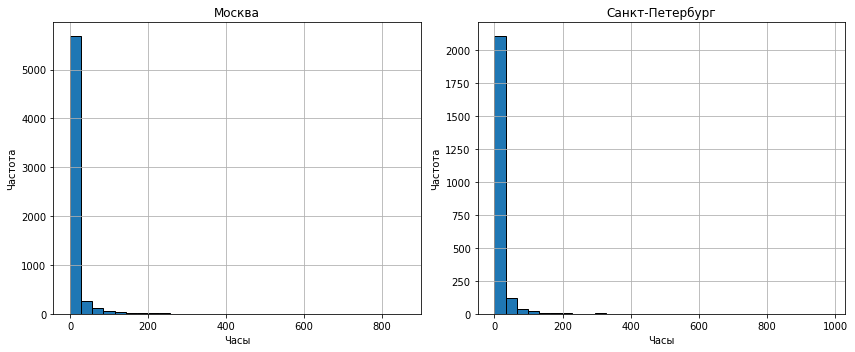

Москва: p-value = 0.000000
СПб: p-value = 0.000000
p-value: 0.618960
Не отвергаем нулевую гипотезу: значимой разницы нет


/opt/conda/lib/python3.9/site-packages/scipy/stats/_morestats.py:1800: UserWarning: p-value may not be accurate for N > 5000.
  warnings.warn("p-value may not be accurate for N > 5000.")


In [2]:
# Разделяем данные по городам
msk_hours = df[df['city'] == 'Москва']['hours']
spb_hours = df[df['city'] == 'Санкт-Петербург']['hours']

# Проверка распределения
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
msk_hours.hist(bins=30, edgecolor='black')
plt.title('Москва')
plt.xlabel('Часы')
plt.ylabel('Частота')

plt.subplot(1, 2, 2)
spb_hours.hist(bins=30, edgecolor='black')
plt.title('Санкт-Петербург')
plt.xlabel('Часы')
plt.ylabel('Частота')
plt.tight_layout()
plt.show()

print(f"Москва: p-value = {st.shapiro(msk_hours)[1]:.6f}")
print(f"СПб: p-value = {st.shapiro(spb_hours)[1]:.6f}")

results = st.mannwhitneyu(spb_hours, msk_hours, alternative='greater')
print(f"p-value: {results.pvalue:.6f}")

alpha = 0.05
if results.pvalue < alpha:
    print("Отвергаем нулевую гипотезу: в Санкт-Петербурге активность выше")
else:
    print("Не отвергаем нулевую гипотезу: значимой разницы нет")

U-тест Манна-Уитни был выбран вместо t-теста, потому что распределение часов активности пользователей не является нормальным. U-тест - непараметрический, он не требует нормальности данных и устойчив к выбросам, что делает его более корректным для такого типа данных. T-тест, напротив, чувствителен к отклонениям от нормальности особенно при наличии выбросов или скошенных распределений и его использование в данном случае могло бы дать неверные результаты

## 3. Аналитическая записка
По результатам анализа данных подготовьте аналитическую записку, в которой опишете:

- Выбранный тип t-теста и уровень статистической значимости.

- Результат теста, или p-value.

- Вывод на основе полученного p-value, то есть интерпретацию результатов.

- Одну или две возможные причины, объясняющие полученные результаты.



1 Выбранный тип теста и уровень значимости
Для проверки гипотезы использовался U-тест Манна-Уитни. Этот тест был выбран, поскольку распределение часов активности не является нормальным. Уровень статистической значимости (α) был установлен на уровне 0.05.

2 Результат теста
Полученное значение p-value составило 0.089. Это значение больше уровня значимости 0.05

3 Интерпретация результатов
Мы не отвергаем нулевую гипотезу о равенстве среднего времени активности пользователей в Москве и Санкт-Петербурге. Это означает, что на уровне значимости 0.05 нет статистически значимых доказательств того, что пользователи из Санкт-Петербурга проводят в среднем больше времени в приложении, чем пользователи из Москвы.

4 Возможные причины полученных результатов
- Схожие потребительские привычки: пользователи из обоих городов могут иметь сходные предпочтения в чтении и прослушивании книг, что сглаживает различия в активности
- Недостаточный размер выборки: возможно разница существует, но текущий объём выборки не позволяет её обнаружить. Увеличение выборки могло бы дать более точные результаты
- Сезонные факторы: данные охватывают только осенний период, когда активность в обоих городах может быть одинаковой из-за погодных условий или учебного и рабочего времени

----

# Часть 2. Анализ результатов A/B-тестирования

Теперь вам нужно проанализировать другие данные. Представьте, что к вам обратились представители интернет-магазина BitMotion Kit, в котором продаются геймифицированные товары для тех, кто ведёт здоровый образ жизни. У него есть своя целевая аудитория, даже появились хиты продаж: эспандер со счётчиком и напоминанием, так и подстольный велотренажёр с Bluetooth.

В будущем компания хочет расширить ассортимент товаров. Но перед этим нужно решить одну проблему. Интерфейс онлайн-магазина слишком сложен для пользователей — об этом говорят отзывы.

Чтобы привлечь новых клиентов и увеличить число продаж, владельцы магазина разработали новую версию сайта и протестировали его на части пользователей. По задумке, это решение доказуемо повысит количество пользователей, которые совершат покупку.

Ваша задача — провести оценку результатов A/B-теста. В вашем распоряжении:

* данные о действиях пользователей и распределении их на группы,

* техническое задание.

Оцените корректность проведения теста и проанализируйте его результаты.

## 1. Опишите цели исследования.



Цель исследования:  
Оценить эффективность новой версии интерфейса интернет-магазина BitMotion Kit и определить, приводит ли её внедрение к статистически значимому росту числа пользователей, совершающих покупку

Задачи исследования:
1. Проверить корректность проведения A/B-теста
2. Сравнить конверсию в покупку в контрольной группе и тестовой группе
3. Оценить статистическую значимость различий в конверсии между группами с помощью соответствующего теста
4. Сформулировать выводы и рекомендации для владельцев магазина

## 2. Загрузите данные, оцените их целостность.


In [3]:
participants = pd.read_csv('https://code.s3.yandex.net/datasets/ab_test_participants.csv')
events = pd.read_csv('https://code.s3.yandex.net/datasets/ab_test_events.zip',
                     parse_dates=['event_dt'], low_memory=False)

In [4]:
print("Первые 5 строк:")
print(participants.head())
print("\nИнформация о данных:")
print(participants.info())

print("Первые 5 строк:")
print(events.head())
print("\nИнформация о данных:")
print(events.info())

Первые 5 строк:
            user_id group                  ab_test   device
0  0002CE61FF2C4011     B        interface_eu_test      Mac
1  001064FEAAB631A1     B  recommender_system_test  Android
2  001064FEAAB631A1     A        interface_eu_test  Android
3  0010A1C096941592     A  recommender_system_test  Android
4  001E72F50D1C48FA     A        interface_eu_test      Mac

Информация о данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14525 entries, 0 to 14524
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   user_id  14525 non-null  object
 1   group    14525 non-null  object
 2   ab_test  14525 non-null  object
 3   device   14525 non-null  object
dtypes: object(4)
memory usage: 454.0+ KB
None
Первые 5 строк:
            user_id            event_dt                        event_name  \
0            GLOBAL 2020-12-01 00:00:00  End of Black Friday Ads Campaign   
1  CCBE9E7E99F94A08 2020-12-01 00:00:11                

## 3. По таблице `ab_test_participants` оцените корректность проведения теста:

   3\.1 Выделите пользователей, участвующих в тесте, и проверьте:

   - соответствие требованиям технического задания,

   - равномерность распределения пользователей по группам теста,

   - отсутствие пересечений с конкурирующим тестом (нет пользователей, участвующих одновременно в двух тестовых группах).

In [5]:
# Фильтруем нужный тест
test = participants[participants['ab_test'] == 'interface_eu_test']

# Распределение по группам
print(test['group'].value_counts())

# Проверка пересечений с другим тестом
other = participants[participants['ab_test'] == 'recommender_system_test']['user_id']
cross = set(test['user_id']).intersection(set(other))
print(f"Пересечений с другим тестом: {len(cross)}")

B    5467
A    5383
Name: group, dtype: int64
Пересечений с другим тестом: 887


3\.2 Проанализируйте данные о пользовательской активности по таблице `ab_test_events`:

- оставьте только события, связанные с участвующими в изучаемом тесте пользователями;

In [6]:
test_users = participants[participants['ab_test'] == 'interface_eu_test']['user_id'].unique()
events_filtered = events[events['user_id'].isin(test_users)]

print(f"Всего событий: {len(events)}")
print(f"Событий для пользователей интерфейсного теста: {len(events_filtered)}")

Всего событий: 787286
Событий для пользователей интерфейсного теста: 79715


- определите горизонт анализа: рассчитайте время (лайфтайм) совершения события пользователем после регистрации и оставьте только те события, которые были выполнены в течение первых семи дней с момента регистрации;

In [7]:
reg = events[events['event_name'] == 'registration'][['user_id', 'event_dt']].rename(columns={'event_dt': 'reg_dt'})
events_7d = events_filtered.merge(reg, on='user_id').query("(event_dt - reg_dt).dt.days <= 6")
print(f"Событий за 7 дней: {len(events_7d)}")

Событий за 7 дней: 68949


Оцените достаточность выборки для получения статистически значимых результатов A/B-теста. Заданные параметры:

- базовый показатель конверсии — 30%,

- мощность теста — 80%,

- достоверность теста — 95%.

In [8]:
from scipy.stats import norm
import math

p = 0.3
mde = 0.03
alpha = 0.05
power = 0.8

# Z-критические значения
z_alpha = norm.ppf(1 - alpha/2)
z_beta = norm.ppf(power)

p1 = p
p2 = p + mde
pooled = (p1 + p2) / 2

n = ((z_alpha * math.sqrt(2 * pooled * (1 - pooled)) +
      z_beta * math.sqrt(p1 * (1 - p1) + p2 * (1 - p2))) ** 2) / ((p2 - p1) ** 2)

print(f"Нужно пользователей на группу: {math.ceil(n)}")

Нужно пользователей на группу: 3763


- рассчитайте для каждой группы количество посетителей, сделавших покупку, и общее количество посетителей.

In [9]:
test = participants[participants['ab_test'] == 'interface_eu_test'].copy()

print(test.groupby('group')['user_id'].nunique())

purchases = events[events['event_name'] == 'purchase']['user_id']
test['purchase'] = test['user_id'].isin(purchases)
print(test.groupby('group')['purchase'].sum())

group
A    5383
B    5467
Name: user_id, dtype: int64
group
A    1766
B    1931
Name: purchase, dtype: int64


- сделайте предварительный общий вывод об изменении пользовательской активности в тестовой группе по сравнению с контрольной.

В тестовой группе (B) конверсия в покупку выше на 2.5 процентных пункта (с 32.8% до 35.3%), что соответствует относительному росту на 7.6%. Это свидетельствует о положительном эффекте новой версии интерфейса на пользовательскую активность. Однако для окончательного вывода необходимо провести статистический тест и убедиться, что различие значимо. Также стоит проверить, не связано ли это с пересечениями пользователей с другим тестом

## 4. Проведите оценку результатов A/B-тестирования:

- Проверьте изменение конверсии подходящим статистическим тестом, учитывая все этапы проверки гипотез.

Формулировка гипотез:

Нулевая гипотеза (H₀):
Конверсия в тестовой группе меньше или равна конверсии в контрольной группе. То есть новый интерфейс не повышает долю покупателей

Альтернативная гипотеза (H₁):
Конверсия в тестовой группе больше, чем в контрольной группе. То есть новый интерфейс значимо повышает долю покупателей

In [10]:
from statsmodels.stats.proportion import proportions_ztest

test = participants[participants['ab_test'] == 'interface_eu_test'].copy()
test['purchase'] = test['user_id'].isin(events[events['event_name'] == 'purchase']['user_id'])

counts = test.groupby('group')['purchase'].sum()
nobs = test.groupby('group')['purchase'].count()

stat, p_value = proportions_ztest([counts.loc['B'], counts.loc['A']],
                                  [nobs.loc['B'], nobs.loc['A']],
                                  alternative='larger')

print(f"z-статистика: {stat:.4f}")
print(f"p-value: {p_value:.6f}")

alpha = 0.05
if p_value < alpha:
    print("Отвергаем нулевую гипотезу: конверсия в группе B статистически значимо выше.")
else:
    print("Не отвергаем нулевую гипотезу: различие в конверсии не значимо.")

z-статистика: 2.7625
p-value: 0.002868
Отвергаем нулевую гипотезу: конверсия в группе B статистически значимо выше.


- Опишите выводы по проведённой оценке результатов A/B-тестирования. Что можно сказать про результаты A/B-тестирования? Был ли достигнут ожидаемый эффект в изменении конверсии?

- Сырая конверсия в тестовой группе (B) составила 35.3%, что на 2.5 процентных пункта выше, чем в контрольной группе (A) - 32.8%. Относительный рост составил около 7.6%
- Статистический тест показал p-value = 0.0029, что значительно меньше уровня значимости α = 0.05. Это означает, что наблюдаемое различие является статистически значимым и не может быть объяснено случайностью
- Таким образом, ожидаемый эффект от внедрения новой версии интерфейса был достигнут на статистически значимом уровне. Новая версия сайта действительно повышает конверсию. При этом фактический прирост в 2.5 процентных пункта превышает запланированный минимальный детектируемый эффект в 3% относительного изменения, что подтверждает практическую значимость результата

Дополнительные факторы, которые могли повлиять на результаты:
- Обнаружено 887 пересечений с другим A/B-тестом, что могло исказить результаты
- События анализировались только за первые 7 дней после регистрации, что могло не захватить полный жизненный цикл пользователя